In [1]:
import ast
from datetime import datetime
import random
from scripts.make_mastertables import count_no_of_gaps, find_DEL_closest_to_cut, find_min_and_max_gap_ranges, find_DEL_around_cut_range, size_of_del_around_the_cut, gap_span_analysed_window, return_shifted_DEL_range, return_category_of_DEL, return_cut_type_based_on_cut_categories, find_microhomology
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get current date and time
now = datetime.now()
# Format the date to YYMMDD
date = now.strftime('%y%m%d')

In [2]:
# This function generates a random nucleotide sequence containing A, T, C and G letters in a lenght of 100 charecters. In the sequence radomly occur deletions represented as '-', those deletions are 0-100 charecters long and replacing A, T, C and G characters. Number of such deletions is 0-2.

def random_nt_seq_generator():
    """
    Generates a random nucleotide sequence of length 100 with deletions represented as '-'.
    The deletions are randomly placed in the sequence and can be of variable length.
    In the middle od the sequence is predicted 'cut_site' = 50 followed by PAM -> two 'G' nucleotides are at positions 54 and 55.
    """

    # Generate a random nucleotide sequence of length 100
    sequence_length = 100
    nucleotides = ['A', 'T', 'C', 'G']
    Reference_Sequence = ''.join(random.choices(nucleotides, k=sequence_length))
    # Set position  54 and 55 as 'GG' to represent PAM sequence
    Reference_Sequence = Reference_Sequence[:54] + 'GG' + Reference_Sequence[56:]

    # Randomise start and end positions, firstly set where the gap opens and then if it goes upstrem or downstream
    r = random.randint(0, 1)
    gap_border = random.randint(1, sequence_length)
    if r == 0:
        start_pos = random.randint(1, gap_border)
        end_pos = gap_border
    else:
        start_pos = gap_border
        end_pos = random.randint(gap_border, sequence_length)       

    # Replace the selected range with '-'
    Aligned_Sequence = Reference_Sequence[:start_pos-1] + '-' * (end_pos - start_pos + 1) + Reference_Sequence[end_pos:]
    # print(Reference_Sequence[:start_pos-1])
    # print(Reference_Sequence[end_pos:])
    return Aligned_Sequence, Reference_Sequence, start_pos, end_pos

def generate_random_sequences_to_file(filename, num_sequences=100):
    with open(filename, 'w') as file:
        file.write("Aligned_Sequence\tReference_Sequence\n")
        for _ in range(num_sequences):
            Aligned_Sequence, Reference_Sequence, start_pos, end_pos = random_nt_seq_generator()
            # file.write(Aligned_Sequence + '\t' + Reference_Sequence + '\t' + str(start_pos) + '\t' + str(end_pos) + '\n')
            file.write(Aligned_Sequence + '\t' + Reference_Sequence + '\n')

def unedited(aligned_sequence, reference_sequence):
    if aligned_sequence == reference_sequence:
        return True
    else:
        return False

def apply_find_microhomology(df, func, new_column_names):
    """Adds new columns into table based on the function find_microhomology."""
    results = df.apply(lambda row: func(row['Gap_closest_to_cut_range'][0],
                                        row['Gap_closest_to_cut_range'][1],
                                        row['Gap_span_analysed_window'],
                                        row['Aligned_Sequence'],
                                        row['Reference_Sequence']), axis=1)
    # Unpack results into separate columns
    for i, col_name in enumerate(new_column_names):
        df[col_name] = [result[i] for result in results]


In [3]:
# # Generate a random nucleotide sequence with deletions into a csv file for 100 sequences and name them as 'Reference_Sequence' and 'Aligned_Sequence'

# output_filename = "../../CRISPRlysis_outputs/random/random_sequences.tsv"
# num_sequences = 100 #1000000 7 seconds

# generate_random_sequences_to_file(output_filename, num_sequences=num_sequences)
# print(f"Generated {num_sequences} random nucleotide sequences with deletions in '{output_filename}'")


In [4]:
# # 1000000 15 seconds
# df = pd.read_csv(output_filename, sep='\t')

# # Add columns to the dataframe as it would be the CRIPSResso2 output
# df['Unedited'] = df.apply(lambda row: unedited(row['Aligned_Sequence'], row['Reference_Sequence']), axis=1)
# df['n_deleted'] = df.apply(lambda row: row['Aligned_Sequence'].count('-'), axis=1)
# df['n_inserted'] = 0
# df['n_mutated'] = 0
# df['#Reads'] = 1
# df['%Reads'] = 1/df.shape[0]
# df['gRNA_seq'] = df.apply(lambda row: row['Reference_Sequence'][33:53], axis=1)
# df['sample'] = 'random_1_SpCas9_none_1_none_1_0_1'


# # Save dataframe to a new file
# output_filename = "../../CRISPRlysis_outputs/random/random_sequences_CRISPResso2_like.tsv"
# df.to_csv(output_filename, sep='\t', index=False)
# print(f"Saved the dataframe with CRISPResso2-like columns to '{output_filename}'")
# df.shape

In [5]:

num_sequences = 100000
# 100000 seuences 100 times in 40 minutes

# Read from parameters.txt file information about 'cut_position','cut_maximum', 'cut_minimum'

# Load parameters.txt as dictionary
with open('./parameters.txt', 'r', encoding='utf-8') as file:
    file_content = file.read()
    parameters = ast.literal_eval(file_content)

cut_position = parameters['cut_position']
cut_maximum = parameters['cut_maximum']
cut_minimum = parameters['cut_minimum']

columns_to_keep = [
    "Aligned_Sequence",
    "Reference_Sequence",
    "n_deleted",
    "#Reads",
    "%Reads",
    "Original_Sequence_around_cut",
    "Aligned_Sequence_around_cut",
    "Gap_category_1",
    "Gap_category_2",
    "Cut_type",
    "End_participating_on_MH",
    "DEL_orientation",
    "End_3_5",
    "Likely_cut_type"
]

j = 0
for i in range(0, 100):
    output_filename = "../../CRISPRlysis_outputs/random/random_sequences.tsv"
    generate_random_sequences_to_file(output_filename, num_sequences=num_sequences)
    df = pd.read_csv(output_filename, sep='\t')
    output_filename = "../../CRISPRlysis_outputs/random/random_sequences_CRISPResso2_like.tsv"
    # Add columns to the dataframe as it would be the CRIPSResso2 output
    df['Unedited'] = df.apply(lambda row: unedited(row['Aligned_Sequence'], row['Reference_Sequence']), axis=1)
    df['n_deleted'] = df.apply(lambda row: row['Aligned_Sequence'].count('-'), axis=1)
    df['n_inserted'] = 0
    df['n_mutated'] = 0
    df['#Reads'] = 1
    df['%Reads'] = 1/df.shape[0]
    df['gRNA_seq'] = df.apply(lambda row: row['Reference_Sequence'][33:53], axis=1)
    df['sample'] = 'random_1_SpCas9_none_1_none_1_0_1'
    df.to_csv(output_filename, sep='\t', index=False)

    # Run CRISPRlysis.py script
    %run CRISPRlysis.py

    # Read the CRISPRlysis output file
    crisprlysis_output_filename = f"../../CRISPRlysis_outputs/random_2025/01_mastertable_{date}.tsv"
    # Filter DataFrame to keep only the selected columns
    filtered_df = df[columns_to_keep]
    # Filter out rows Gap_category_1 == 97
    filtered_df = filtered_df[filtered_df["Gap_category_1"] != 97]
    # Create a new column with the combination of the columns
    filtered_df['Combination'] = filtered_df['Gap_category_1'].astype(str) + '_' + filtered_df['Gap_category_2'].astype(str) + '_' + filtered_df['Cut_type'].astype(str) + '_' + filtered_df['End_participating_on_MH'].astype(str) + '_' + filtered_df['DEL_orientation'].astype(str) + '_' + filtered_df['End_3_5'].astype(str) + '_' + filtered_df['Likely_cut_type'].astype(str)
    # Group by the new column and sum the "%Reads" and keep columns "Combination" and "#Reads"
    grouped_df = filtered_df.groupby('Combination').agg({'%Reads': 'sum', '#Reads': 'sum'}).reset_index()
    # make columns "Gap_category_1", "Gap_category_2", "Cut_type", "End_participating_on_MH", "DEL_orientation", "End_3_5", "Likely_cut_type" by spliting the Combination by _
    grouped_df[['Gap_category_1', 'Gap_category_2', 'Cut_type', 'End_participating_on_MH', 'DEL_orientation', 'End_3_5', 'Likely_cut_type']] = grouped_df['Combination'].str.split('_', expand=True)
    grouped_df['Gap_category_1'] = grouped_df['Gap_category_1'].astype(int)
    grouped_df['iteration'] = j+1

    if j == 0:
        # Save the grouped DataFrame to a new file
        output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
        grouped_df.to_csv(output_filename, sep='\t', index=False, mode='w')
        print(f"Saved the grouped DataFrame to '{output_filename}'")
    else:
        # upend the grouped DataFrame to the existing file
        output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
        grouped_df.to_csv(output_filename, sep='\t', index=False, mode='a', header=False)
    final_df = pd.read_csv(output_filename, sep='\t')
    print(f"Final DataFrame shape: {final_df.shape}")
    j+=1



Report from Random 2025 from date 250522.
Project output dir already exists and is /home/lefnui/CRISPRlysis_outputs/random_2025.
Cut position is set to location: 50
The project output folder already exists.
{}
Mastertable was created from the unique .tsv file which already contained gRNA seq.
00_mastertable shape: (100000, 54)
Making 01_mastertable.
01_mastertable_250522.tsv with shape (100000, 66) was created.

Processing /home/lefnui/CRISPRlysis_outputs/random_2025/01_mastertable_250522.tsv and []
###########################
# Analysing next subtable #
###########################
Processing /home/lefnui/CRISPRlysis_outputs/random_2025/01_mastertable_250522.tsv
The project output folder already exists.
New project_output_subdir is ../../CRISPRlysis_outputs/random_2025/250522
Analysed 100000 gRNAs in 1 biological replicates.
Saved the grouped DataFrame to '../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_-2_50_2_250522.tsv'
Final DataFrame shape: (71, 11)
Report from Rand

In [6]:
output_filename = f"../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"

# Load the final DataFrame
final_df = pd.read_csv(output_filename, sep='\t')
iterations = final_df['iteration'].max()

#  group by the 'Combination' column and sum the #Reads and divide it by the number of iterations
df_grouped = final_df.groupby(['Combination'])['#Reads'].agg(['sum']).reset_index()
df_grouped['NormReads'] = df_grouped['sum'] / iterations
# Normalise the 'normReads' column by dividing it by the column 'sum'
df_grouped['NormReads'] = 100*df_grouped['NormReads'] / df_grouped['NormReads'].sum()
# Sort by the 'NormReads' column in descending order
df_grouped = df_grouped.sort_values(by='NormReads', ascending=False)
# Save the grouped DataFrame to a new file
output_filename = f"../../CRISPRlysis_outputs/random_2025/random_categories_grouped_norm_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.tsv"
df_grouped.to_csv(output_filename, sep='\t', index=False)
print(f"Saved the grouped DataFrame to '{output_filename}'")
df_grouped

Saved the grouped DataFrame to '../../CRISPRlysis_outputs/random_2025/random_categories_grouped_norm_-2_50_2_250522.tsv'


,Combination,sum,NormReads
69,6_6_C_X_B_0_0,1689918,18.011934
6,12_12_O_X_D_0_0,1564774,16.678091
11,1_1_O_X_U_0_0,1564125,16.671173
68,6_6_C_C_B_0_0,1264329,13.475808
5,12_12_O_C_D_0_0,1192492,12.710136
...,...,...,...
52,5_11_1_U_D_3_1,5,0.000053
8,1_11_0_C_C_0_1,4,0.000043
54,5_12_1_U_D_3_1,3,0.000032
23,2_12_0_C_C_0_1,2,0.000021


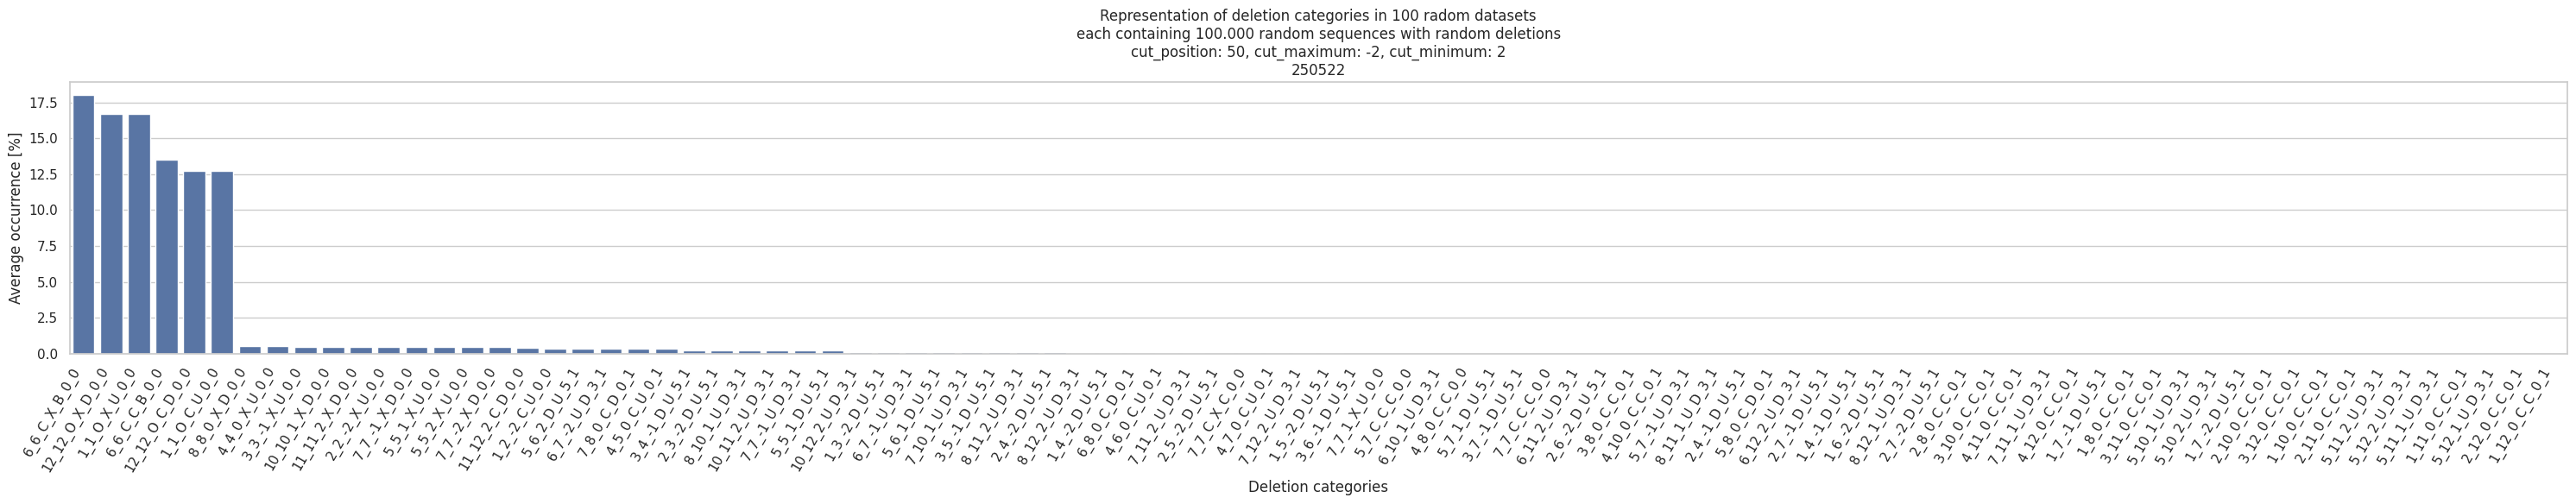

In [7]:
# Plot the Combination vs NormReads
## df_grouped['NormReads'] = df_grouped['sum'] / iterations
## df_grouped['NormReads'] = 100*df_grouped['NormReads'] / df_grouped['NormReads'].sum()

plt.figure(figsize=(df_grouped.shape[0]/3, 6))
sns.set_theme(style="whitegrid")
sns.barplot(x='Combination', y='NormReads', data=df_grouped)
plt.xticks(rotation=60, ha='right')
plt.xlabel('Deletion categories')
plt.ylabel('Average occurrence [%]')
plt.title(f'Representation of deletion categories in {iterations} radom datasets\neach containing 100.000 random sequences with random deletions\ncut_position: {cut_position}, cut_maximum: {cut_maximum}, cut_minimum: {cut_minimum}\n{date}')
plt.tight_layout()
plt.savefig(f'../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{cut_maximum}_{cut_position}_{cut_minimum}_{date}.png', dpi=300)
plt.show()


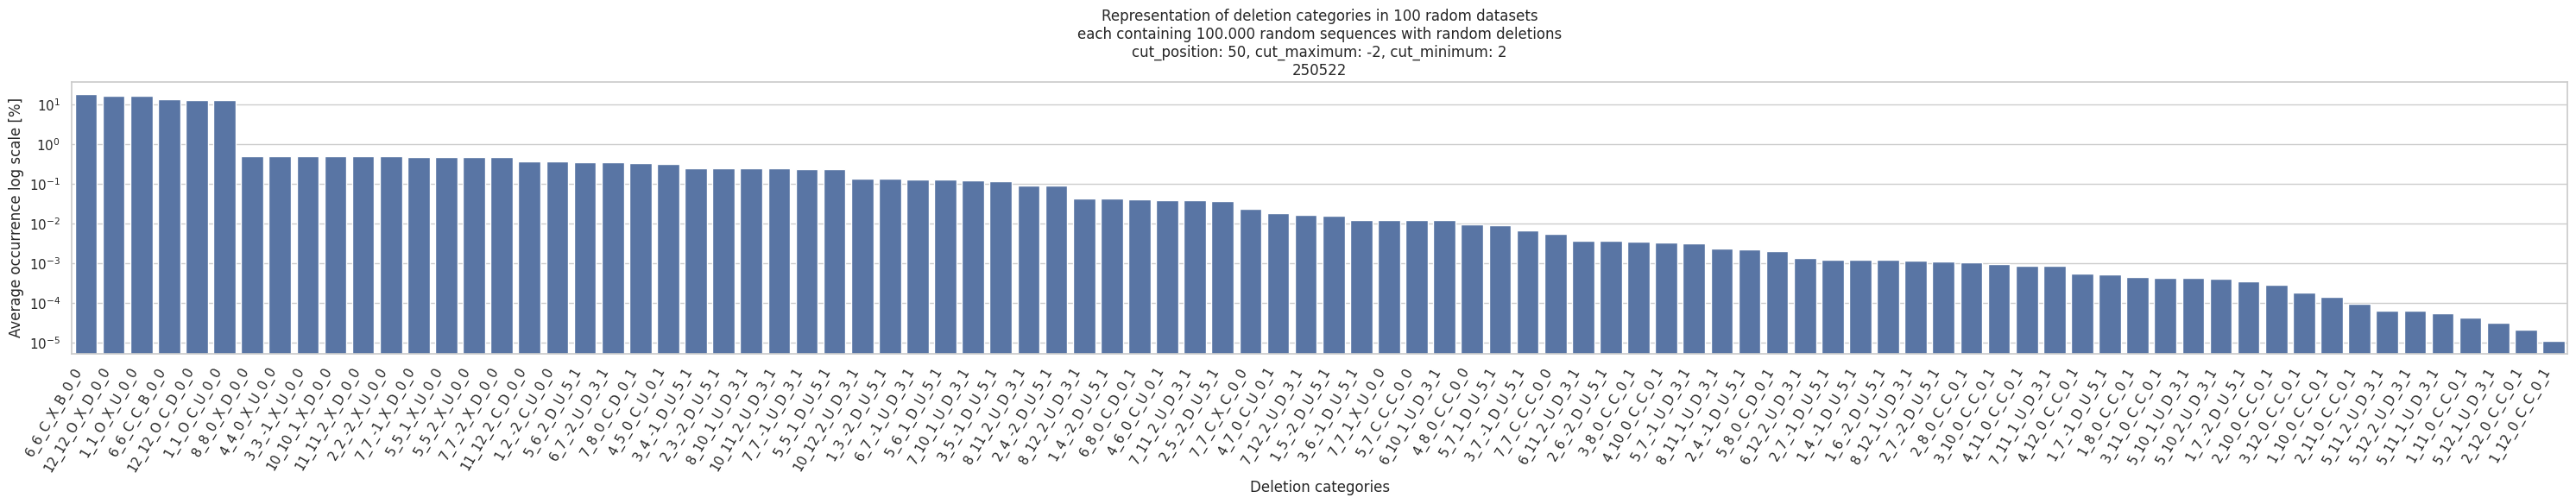

In [8]:
# Plot the Combination vs NormReads with log scale
plt.figure(figsize=(df_grouped.shape[0]/3, 6))
sns.set_theme(style="whitegrid")
sns.barplot(x='Combination', y='NormReads', data=df_grouped)
plt.xticks(rotation=60, ha='right')
plt.xlabel('Deletion categories')
plt.ylabel('Average occurrence log scale [%]')
plt.yscale('log')
plt.title(f'Representation of deletion categories in {iterations} radom datasets\neach containing 100.000 random sequences with random deletions\ncut_position: {cut_position}, cut_maximum: {cut_maximum}, cut_minimum: {cut_minimum}\n{date}')
plt.tight_layout()
plt.savefig(f'../../CRISPRlysis_outputs/random_2025/random_sequences_grouped_{cut_maximum}_{cut_position}_{cut_minimum}_log_{date}.png', dpi=300)
plt.show()